# Analytic Bunch-Davies modes

*Analytic results checked by substitution.*

All computations call `desitter_qft`; see the matching `docs/` file for derivations.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from IPython.display import Image, display
from desitter_qft.plotting import apply_style; apply_style()
FIG = os.path.abspath(os.path.join('..', 'figures'))

In [2]:
import mpmath as mp
from desitter_qft.analytic_modes import *
from desitter_qft.normalization import wronskian_residual
eta = np.linspace(-40, -0.01, 400)
for nu in (0.5, 1.0, 1.2689, 1.5, 0.8j):
    v = bunch_davies_mode(eta, 1.0, nu); dv = bunch_davies_mode_derivative(eta, 1.0, nu)
    print(f'nu={nu}: max|W-i| = {wronskian_residual(v, dv).max():.2e}')
nu, k = 1.2689, 1.0
f = lambda e: 0.5*mp.sqrt(mp.pi)*mp.exp(1j*mp.pi*(nu/2+0.25))*mp.sqrt(-e)*mp.hankel1(nu, -k*e)
print('ODE residual by substitution:', [float(abs(mp.diff(f, e, 2) + (k**2 - (nu**2-0.25)/e**2)*f(e))) for e in (-3.0, -0.7, -0.1)])

nu=0.5: max|W-i| = 8.88e-16
nu=1.0: max|W-i| = 3.44e-13
nu=1.2689: max|W-i| = 2.83e-13
nu=1.5: max|W-i| = 2.66e-15


nu=0.8j: max|W-i| = 5.55e-16
ODE residual by substitution: [1.8875832159447664e-16, 5.4672143489065705e-16, 1.8198773652309366e-13]


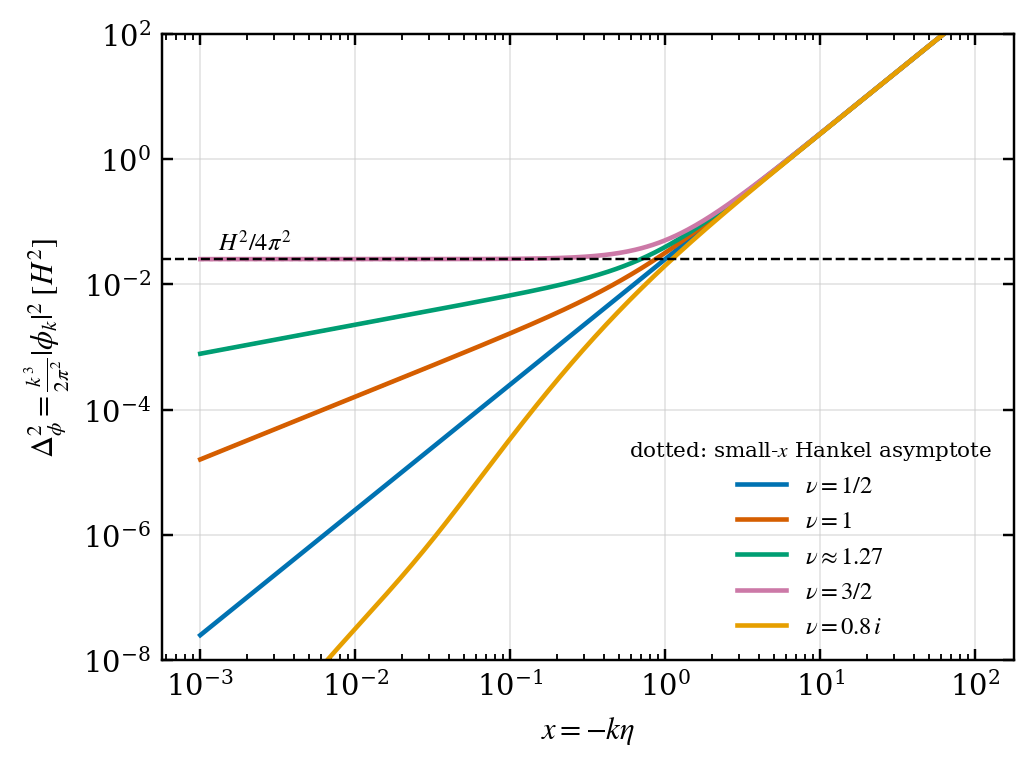

In [3]:
display(Image(os.path.join(FIG, 'fig04_power_spectra.png')))